# Matrix Factorization — From Clustering to the Netflix Prize

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ujjwal091/ai-ml-course/blob/main/modules/02-unsupervised-learning/matrix-factorization/notes.ipynb)

*Picks up from [Recommender Systems](../recommender-systems/notes.ipynb), which ended with a first matrix
factorization. Here we go deeper: K-Means turns out to be matrix factorization too, and the same idea scales up
to what won the Netflix Prize.*


## 1. The big picture

A lot of methods we've met — clustering, dimensionality reduction, recommendation — are one problem in different
clothes:

> Given a data matrix $X$ ($n \times p$), find two smaller matrices $W$ and $H$ so that $X \approx W H$.
> Make the reconstruction error as small as possible, **subject to some rules (constraints) on $W$ and $H$**.

The methods differ only in those rules. This notebook walks through them one by one:

| Method | Rule on the matrices |
|---|---|
| K-Means | each row of the assignment matrix is one-hot (0/1, exactly one 1) |
| GMM | each row of the assignment matrix is fractions that add up to 1 |
| Non-negative MF (NMF) | every number in both matrices is ≥ 0 |
| Recommender MF | only fit the ratings we actually know |


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import NMF, TruncatedSVD

## 2. First, one tool: the Frobenius norm

To say "reconstruction error", we need one number for how far two matrices are apart. The **Frobenius norm** of a
matrix is the length of all its entries laid out in one long list: square every entry, add them up, take the
square root.

$$
\|A\|_F = \sqrt{\sum_{i,j} a_{ij}^2}
$$


In [2]:
A = np.array([[3, 4],
              [0, 5]])
print("By hand: sqrt(3² + 4² + 0² + 5²) = sqrt(50) =", round(np.sqrt(50), 3))
print("NumPy:  ", round(np.linalg.norm(A, "fro"), 3))

By hand: sqrt(3² + 4² + 0² + 5²) = sqrt(50) = 7.071
NumPy:   7.071


**Why this helps.** To measure how good a factorization $R \approx U V^T$ is, subtract the rebuilt matrix from the
real one and take the Frobenius norm of what's left: $\|R - UV^T\|_F$. Smaller = better. Here is a tiny example
with a single "taste" (`d = 1`):


In [3]:
R = np.array([[4.0, 3.0],
              [2.0, 1.0]])
U = np.array([[1.8], [0.9]])       # one number per user
V = np.array([[2.2], [1.6]])       # one number per item
rebuilt = U @ V.T

print("Rebuilt from U·Vᵀ:\n", rebuilt.round(2))
print("\nLeft-over error (R − UVᵀ):\n", (R - rebuilt).round(2))
print(f"\nReconstruction error ‖R − UVᵀ‖_F = {np.linalg.norm(R - rebuilt, 'fro'):.3f}")

Rebuilt from U·Vᵀ:
 [[3.96 2.88]
 [1.98 1.44]]

Left-over error (R − UVᵀ):
 [[ 0.04  0.12]
 [ 0.02 -0.44]]

Reconstruction error ‖R − UVᵀ‖_F = 0.458


## 3. K-Means is matrix factorization

Take 6 Veloura customers described by 3 numbers (orders per year, average basket ₹, return rate), grouped into 3
clusters by K-Means:


In [4]:
X = np.array([
    [26, 3200, 0.05], [24, 3000, 0.07],      # frequent, mid-spend
    [4, 8800, 0.15],  [5, 9300, 0.12],       # rare, big-ticket
    [12, 1500, 0.40], [11, 1400, 0.45],      # medium, returns a lot
])
X_scaled = (X - X.mean(axis=0)) / X.std(axis=0)

km = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X_scaled)
print("Cluster of each customer:", km.labels_)

Cluster of each customer: [2 2 0 0 1 1]


Now write the same answer as two matrices:

- **Assignment matrix** $Z$ ($n \times k$): one row per customer, one column per cluster, a `1` where the customer
  belongs.
- **Centroid matrix** $C$ ($k \times p$): one row per cluster, holding its centre point.

Multiply them: $Z \cdot C$ gives back, for each customer, **the centroid of their cluster** — an approximation of
the customer's own row.


In [5]:
Z = np.eye(3)[km.labels_]            # one-hot rows
C = km.cluster_centers_

print("Z (assignment, 6×3):\n", Z.astype(int))
print("\nC (centroids, 3×3):\n", C.round(2))
print("\nZ·C (each customer replaced by their centroid):\n", (Z @ C).round(2))

Z (assignment, 6×3):
 [[0 0 1]
 [0 0 1]
 [1 0 0]
 [1 0 0]
 [0 1 0]
 [0 1 0]]

C (centroids, 3×3):
 [[-1.07  1.38 -0.45]
 [-0.25 -0.94  1.38]
 [ 1.33 -0.44 -0.93]]

Z·C (each customer replaced by their centroid):
 [[ 1.33 -0.44 -0.93]
 [ 1.33 -0.44 -0.93]
 [-1.07  1.38 -0.45]
 [-1.07  1.38 -0.45]
 [-0.25 -0.94  1.38]
 [-0.25 -0.94  1.38]]


And the thing K-Means tries to minimise — **inertia**, the squared distance from every point to its centroid — is
exactly the squared Frobenius error of this factorization:


In [6]:
print(f"‖X − Z·C‖²_F = {np.linalg.norm(X_scaled - Z @ C, 'fro') ** 2:.4f}")
print(f"KMeans inertia = {km.inertia_:.4f}")

‖X − Z·C‖²_F = 0.1309
KMeans inertia = 0.1309


Same number. So **K-Means = factorize $X \approx ZC$, where each row of $Z$ must be one-hot.** That one-hot rule
is why every customer lands in exactly one cluster ("hard clustering"). $Z$ must be 0/1 because it records
*membership*; $C$ has no such rule because it holds *coordinates*, which can be negative or any size.

**Relax the rule → GMM.** Allow each row of $Z$ to hold fractions that add up to 1 (like `0.2, 0.3, 0.5`) and you
get soft clustering — a customer can be 70% in one group and 30% in another. That is exactly what
[GMM](../gaussian-mixture-models/notes.ipynb) gives us.


In [7]:
# Two overlapping groups of customers, so some people really sit "in between"
rng_g = np.random.default_rng(4)
X_overlap = np.vstack([rng_g.normal([0, 0], 1.0, (40, 2)), rng_g.normal([2.2, 0], 1.0, (40, 2))])
gmm = GaussianMixture(n_components=2, random_state=0, n_init=5).fit(X_overlap)
Z_soft = gmm.predict_proba(X_overlap)

unsure = np.where(Z_soft.max(axis=1) < 0.85)[0][:4]
print("A few in-between customers (each row adds to 1):")
print(pd.DataFrame(Z_soft[unsure], columns=["group A", "group B"]).round(2))
print("\nEvery row adds to 1:", np.allclose(Z_soft.sum(axis=1), 1))

A few in-between customers (each row adds to 1):
   group A  group B
0     0.18     0.82
1     0.26     0.74
2     0.84     0.16
3     0.85     0.15

Every row adds to 1: True


Each in-between customer belongs partly to both groups. One-hot K-Means would force a 0 or 1.


## 4. Non-negative matrix factorization (NMF) — factors you can read

Plain factorization lets the numbers go negative, which makes them hard to explain: what does "−0.7 of a
shopping mission" mean? **NMF** adds one rule: every number in both matrices must be ≥ 0. Then a customer can
only be built by *adding* pieces together, never by cancelling them. The factors become "parts".

Example: how many items each of 8 customers bought in 4 product categories.


In [8]:
categories = ["jeans", "tees", "dresses", "heels", "sneakers", "joggers"]
purchases = pd.DataFrame([
    [5, 4, 0, 0, 0, 0],
    [4, 6, 1, 0, 0, 0],
    [0, 0, 5, 4, 0, 0],
    [1, 0, 6, 5, 0, 1],
    [0, 1, 0, 0, 5, 6],
    [0, 0, 0, 1, 4, 5],
    [4, 5, 0, 0, 4, 5],
    [0, 0, 6, 4, 1, 0],
], columns=categories, index=[f"cust{i}" for i in range(1, 9)])

nmf = NMF(n_components=3, init="nndsvda", random_state=0, max_iter=500)
W = nmf.fit_transform(purchases)     # customers × parts
H = nmf.components_                  # parts × categories

parts = pd.DataFrame(H, columns=categories, index=["part 1", "part 2", "part 3"]).round(2)
parts

,jeans,tees,dresses,heels,sneakers,joggers
part 1,9.09,10.40,0.38,0.00,0.00,0.05
part 2,0.18,0.00,4.32,3.30,0.04,0.01
part 3,0.00,0.25,0.00,0.16,3.17,3.89


Each row is a "part" — a bundle of categories that tend to be bought together. Reading them: one part is
jeans + tees (everyday wear), one is dresses + heels (dress-up), one is sneakers + joggers (athleisure). We never
told the model these themes; they came from the numbers, and since nothing is negative, we can read them directly.


In [9]:
pd.DataFrame(W, index=purchases.index, columns=["part 1", "part 2", "part 3"]).round(2)

,part 1,part 2,part 3
cust1,0.46,0.00,0.00
cust2,0.52,0.11,0.00
cust3,0.00,1.18,0.00
cust4,0.03,1.43,0.14
cust5,0.03,0.00,1.56
cust6,0.00,0.09,1.28
cust7,0.45,0.00,1.27
cust8,0.00,1.32,0.12


Each customer is a **mix** of parts. `cust7`, who buys both everyday wear and athleisure, gets weight on two parts
at once — something one-hot K-Means could never say. The price: NMF fits slightly less tightly than unconstrained
factorization. Use it when someone needs to *read* the factors; use plain MF when only the predictions matter.

The same idea works on images: pixel brightness is never negative, so NMF learns **parts-based** pieces — a nose,
an eye, a stroke of a digit — that add up to a whole picture. We'll see this in Section 9.


## 5. Several signals at once — purchases, cart-adds, removals

A store logs more than purchases. Three tables, each customers × products:

- **P** — bought it
- **W** — added to cart (interest, even without buying)
- **D** — removed from cart (a soft "no")

How do we use all three? Three approaches, from worst to best.

**Approach 1 — just add them: $A = P + W + D$.** Broken: a removal is the *opposite* of a purchase, so adding
them mixes "yes" and "no" into one meaningless number.


In [10]:
signals = pd.DataFrame({"purchase": [1, 0, 1], "cart_add": [1, 1, 1], "cart_remove": [0, 0, 1]},
                       index=["bought it", "only carted it", "carted, bought, then removed"])
signals["P+W+D"] = signals.sum(axis=1)
signals

,purchase,cart_add,cart_remove,P+W+D
bought it,1,1,0,2
only carted it,0,1,0,1
"carted, bought, then removed",1,1,1,3


"Bought it" (sum 2) and "carted, bought, then removed" (sum 3) look *more* interested than a clean purchase. The
sum is wrong.

**Approach 2 — weights: $A = \alpha_1 P + \alpha_2 W + \alpha_3 D$.** Purchases strong positive, cart-adds weaker
positive, removals negative — for example `1`, `0.3`, `−1`:


In [11]:
weights = {"purchase": 1.0, "cart_add": 0.3, "cart_remove": -1.0}
signals["weighted"] = (signals["purchase"] * weights["purchase"]
                       + signals["cart_add"] * weights["cart_add"]
                       + signals["cart_remove"] * weights["cart_remove"])
signals[["purchase", "cart_add", "cart_remove", "weighted"]]

,purchase,cart_add,cart_remove,weighted
bought it,1,1,0,1.3
only carted it,0,1,0,0.3
"carted, bought, then removed",1,1,1,0.3


Now the order makes sense: a clean purchase scores highest (1.3), and the removal cancels the purchase
(0.3, same as just carting it). But the three weights are new
hyperparameters. Pick them badly and you quietly bias the whole system, and nobody can say what the "right" ones
are.

**Approach 3 — factorize each table separately, combine at the end.** $P \approx U_1 V_1^T$, $W \approx U_2 V_2^T$,
$D \approx U_3 V_3^T$. Each customer ends up with three separate profile vectors: a *buying* profile, a
*browsing* profile and a *rejection* profile. Nothing is mixed up front, and only when we must decide do we
combine them with plain business logic: **recommend items close to what they buy, and downweight items close to
what they reject.**

Demo: 60 customers, 12 products, where customers who like a product type also tend to remove products of another.


In [12]:
rng = np.random.default_rng(3)
n_cust, n_prod = 60, 12
taste = rng.integers(0, 2, n_cust)                  # 0 = casual lover, 1 = formal lover
prod_type = np.array([0] * 6 + [1] * 6)             # first 6 products casual, last 6 formal

def draw(prob_same, prob_other):
    p = np.where(taste[:, None] == prod_type[None, :], prob_same, prob_other)
    return (rng.random((n_cust, n_prod)) < p).astype(float)

P_mat = draw(0.45, 0.05)         # buy things matching their taste
W_mat = draw(0.60, 0.20)         # browse a bit more widely
D_mat = draw(0.03, 0.30)         # remove things from the *other* style

def factorize(M, d=2):
    model = NMF(n_components=d, init="nndsvda", random_state=0, max_iter=600)
    users = model.fit_transform(M)
    return users, model.components_.T       # (customers × d), (products × d)

U_p, V_p = factorize(P_mat)
U_w, V_w = factorize(W_mat)
U_d, V_d = factorize(D_mat)

def score(u):
    like = U_p[u] @ V_p.T + 0.3 * (U_w[u] @ V_w.T)
    reject = U_d[u] @ V_d.T
    return like - reject

casual_fan = int(np.where(taste == 0)[0][0])
scores = score(casual_fan)
print(f"Customer {casual_fan} (a casual-style customer)")
print("Products 0–5 are casual, 6–11 are formal.")
print("Top 4 recommended products:", [int(k) for k in np.argsort(-scores)[:4]])
print("Bottom 4 products:         ", [int(k) for k in np.argsort(scores)[:4]])

Customer 1 (a casual-style customer)
Products 0–5 are casual, 6–11 are formal.
Top 4 recommended products: [0, 5, 4, 2]
Bottom 4 products:          [6, 9, 10, 8]


The casual customer's top picks come from the casual products (ids 0–5) and the formal ones sink to the bottom —
found by combining three separately learned profiles, with no hand-tuned weights on the raw data. It's more work
up front, but it avoids both the meaningless sum and the fragile weights.


## 6. The Netflix Prize

In 2006 Netflix offered **$1,000,000** to anyone who could improve its recommendation accuracy by **10%**,
measured by RMSE (root mean squared error) on ratings hidden from the contestants. It was awarded in 2009. The
winning ideas were mostly matrix factorization with upgrades. Here is each upgrade, built on data where we know
the truth.

**Base model.** The rating user $u$ gives item $i$ is the dot product of two $d$-number vectors:

$$
\hat{r}_{ui} = q_i^T p_u, \qquad R \approx P Q^T
$$

$p_u$ is the user's vector, $q_i$ the item's, and $d$ is the number of hidden features (the "latent" space). We
train by minimising the squared error over the **known** ratings only:

$$
\min_{p, q} \sum_{(u,i) \text{ known}} (r_{ui} - q_i^T p_u)^2
$$

**Upgrade 1 — regularization.** Without limits, the vectors can grow huge to memorize noise. Add a penalty on
their size, with strength $\lambda$:

$$
\min_{p, q} \sum (r_{ui} - q_i^T p_u)^2 + \lambda \left( \sum_i \|q_i\|^2 + \sum_u \|p_u\|^2 \right)
$$

It tells the model: *"explain the ratings, but don't get too clever, or you'll fail on new data."*

**Training with SGD.** Go through known ratings one at a time. With error $e_{ui} = r_{ui} - q_i^T p_u$ and
learning rate $\gamma$:

$$
q_i \leftarrow q_i + \gamma (e_{ui} \, p_u - \lambda q_i), \qquad p_u \leftarrow p_u + \gamma (e_{ui} \, q_i - \lambda p_u)
$$

**Upgrade 2 — biases.** Some users rate everything high, some are harsh critics; some movies are loved by all.
That has nothing to do with taste. A quick example: the average Netflix rating is 3.7, *Titanic* is rated 0.5 above
average, and Joe is a critic who rates 0.3 below average. Before any "taste" enters, the estimate is already
$3.7 + 0.5 - 0.3 = 3.9$. So:

$$
\hat{r}_{ui} = \mu + b_u + b_i + q_i^T p_u
$$

- $\mu$ — the global average rating
- $b_u$ — how generous or harsh user $u$ is
- $b_i$ — how loved or disliked item $i$ is

All of these are learned. The biases absorb the large, simple effects; the vectors are then free to model what's
left — the real match between a user's taste and an item's character.

Data with real user and item biases built in (and 2 hidden tastes), 40% of ratings known, 20% of those held out:


In [13]:
def make_biased_ratings(n_users=300, n_items=40, fill=0.4, seed=8):
    rng = np.random.default_rng(seed)
    mu = 3.4
    b_u = rng.normal(0, 0.6, n_users)
    b_i = rng.normal(0, 0.6, n_items)
    P = rng.normal(0, 0.8, (n_users, 2))
    Q = rng.normal(0, 0.8, (n_items, 2))
    r = np.clip(np.round(mu + b_u[:, None] + b_i[None, :] + P @ Q.T + rng.normal(0, 0.3, (n_users, n_items))), 1, 5)
    rows, cols = np.where(rng.random((n_users, n_items)) < fill)
    return r, rows, cols

R_full, rows, cols = make_biased_ratings()
test_flag = np.random.default_rng(0).random(len(rows)) < 0.2
tr, te = ~test_flag, test_flag
n_users, n_items = R_full.shape
print(f"{len(rows)} known ratings → train on {tr.sum()}, test on {te.sum()}")

4827 known ratings → train on 3823, test on 1004


In [14]:
def train_sgd(rows, cols, y, d=2, lr=0.01, reg=0.05, epochs=40, use_bias=True, seed=1):
    rng = np.random.default_rng(seed)
    p = rng.normal(0, 0.1, (n_users, d))
    q = rng.normal(0, 0.1, (n_items, d))
    b_u, b_i = np.zeros(n_users), np.zeros(n_items)
    mu = y.mean() if use_bias else 0.0
    for _ in range(epochs):
        for k in rng.permutation(len(rows)):
            u, i = rows[k], cols[k]
            e = y[k] - (mu + b_u[u] + b_i[i] + q[i] @ p[u])
            if use_bias:
                b_u[u] += lr * (e - reg * b_u[u])
                b_i[i] += lr * (e - reg * b_i[i])
            p[u], q[i] = p[u] + lr * (e * q[i] - reg * p[u]), q[i] + lr * (e * p[u] - reg * q[i])
    return mu, b_u, b_i, p, q

def predict(model, rows, cols):
    mu, b_u, b_i, p, q = model
    return mu + b_u[rows] + b_i[cols] + np.einsum("kd,kd->k", p[rows], q[cols])

def rmse(model, mask):
    truth = R_full[rows[mask], cols[mask]]
    return np.sqrt(np.mean((truth - predict(model, rows[mask], cols[mask])) ** 2))

y_train = R_full[rows[tr], cols[tr]]
baseline_rmse = np.sqrt(np.mean((R_full[rows[te], cols[te]] - y_train.mean()) ** 2))

plain = train_sgd(rows[tr], cols[tr], y_train, use_bias=False)
biased = train_sgd(rows[tr], cols[tr], y_train, use_bias=True)

print(f"Always guess the average ({y_train.mean():.2f}):        test RMSE = {baseline_rmse:.3f}")
print(f"MF with regularization, no biases:           test RMSE = {rmse(plain, te):.3f}")
print(f"MF with regularization + biases (μ+b_u+b_i): test RMSE = {rmse(biased, te):.3f}")

Always guess the average (3.18):        test RMSE = 1.204
MF with regularization, no biases:           test RMSE = 0.745
MF with regularization + biases (μ+b_u+b_i): test RMSE = 0.558


Each step helps: factorization beats guessing the average, and adding biases lowers the error again, because the
generous-user and popular-movie effects no longer have to be squeezed into the taste vectors.

**Choosing $\lambda$.** Too small and the model memorizes; too large and it can't learn anything. As always, pick
it by test error:


In [15]:
# A much sparser store (only 10% of ratings known) and a bigger d, where memorizing is a real risk
R_sp, rows_sp, cols_sp = make_biased_ratings(fill=0.1)
test_sp = np.random.default_rng(0).random(len(rows_sp)) < 0.2
y_sp = R_sp[rows_sp, cols_sp]

def rmse_sp(model, mask):
    return np.sqrt(np.mean((y_sp[mask] - predict(model, rows_sp[mask], cols_sp[mask])) ** 2))

for reg in [0.0, 0.05, 0.1, 0.2, 0.4]:
    m = train_sgd(rows_sp[~test_sp], cols_sp[~test_sp], y_sp[~test_sp], d=6, reg=reg, epochs=60)
    print(f"λ = {reg:<4}  train RMSE = {rmse_sp(m, ~test_sp):.3f}   test RMSE = {rmse_sp(m, test_sp):.3f}")

λ = 0.0   train RMSE = 0.403   test RMSE = 1.057


λ = 0.05  train RMSE = 0.493   test RMSE = 1.022


λ = 0.1   train RMSE = 0.571   test RMSE = 1.002


λ = 0.2   train RMSE = 0.675   test RMSE = 0.982


λ = 0.4   train RMSE = 0.756   test RMSE = 0.974


With few ratings and a large `d`, the unregularized model fits its training ratings very closely (0.40) but does
badly on unseen ones (1.06) — it memorized. Increasing λ makes training error worse but **test error better**,
until λ gets large enough that the model can't learn enough. (On the denser data above, regularization wasn't
needed — it matters most when ratings are few.)


**Upgrade 3 — time.** People and films change. A user's generosity drifts; an old movie gets rediscovered;
someone who watched cartoons this year may watch thrillers in five years. The final Netflix models let the biases
and vectors depend on time:

$$
\hat{r}_{ui}(t) = \mu + b_u(t) + b_i(t) + q_i(t)^T p_u(t)
$$

Only $\mu$ stays fixed. In practice this means training on **chunks of time** instead of one big pile — recent
chunks matter more for predicting what happens next. (Modelling things that change over time is exactly what the
[time series](../time-series/notes.ipynb) notebooks are about.) Time awareness is reported to have given
the biggest accuracy gain of all the Netflix Prize upgrades.


## 7. Matrix factorization as feature engineering

Look at what training left us: for every user a $d$-number vector $p_u$, and for every item a vector $q_i$. We
built them to predict ratings, but they are useful **features for any other model** — we get user and item
features "out of thin air", without anyone designing them.

- Similar users end up with similar $p_u$; similar items get similar $q_i$.
- Unlike hand-made features ("country", "PIN code"), these are **not interpretable** — they're just numbers an
  algorithm made up. But they work.

What can we do with them?

- **Cluster** the users into cohorts (K-Means on the $p_u$ vectors).
- **Find similar items** (nearest neighbours of a $q_i$).
- **Feed a model** — e.g. predict whether a user will take a paid subscription.

Demo: use the user vectors we just learned to predict a made-up label — "premium subscriber" — that depends on
taste, a thing the raw rating columns only show indirectly.


In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

mu_, b_u_, b_i_, p_, q_ = biased

# The label is built from the user's TRUE hidden taste (we know it only because we made the data) plus noise —
# never from the vectors the model learned, so there is no cheating.
rng_l = np.random.default_rng(8)
_ = rng_l.normal(0, 0.6, n_users), rng_l.normal(0, 0.6, n_items)      # same draws as make_biased_ratings
true_taste = rng_l.normal(0, 0.8, (n_users, 2))
noise = np.random.default_rng(2).normal(0, 0.3, n_users)
premium = (true_taste[:, 0] + noise > np.median(true_taste[:, 0])).astype(int)

raw = np.zeros((n_users, n_items))
raw[rows[tr], cols[tr]] = R_full[rows[tr], cols[tr]]
mf_features = np.c_[p_, b_u_]

for name, F in [(f"raw rating columns ({n_items} values, mostly 0)", raw), ("MF vectors (3 values)", mf_features)]:
    acc = cross_val_score(LogisticRegression(max_iter=2000), F, premium, cv=5).mean()
    print(f"{name:<42} accuracy = {acc:.2f}")

raw rating columns (40 values, mostly 0)   accuracy = 0.62
MF vectors (3 values)                      accuracy = 0.80


A model on just 3 numbers per user does as well as or better than one on 40 sparse raw columns. That's the point
of a compact, dense representation.


## 8. Same idea on text — document × word matrix

Replace users with **documents** and items with **words**. Build a matrix $A$ with one row per document and one
column per word; $A_{ij}$ is how many times word $j$ appears in document $i$. Factorize $A_{n \times m} \approx
B_{n \times d} \cdot C_{d \times m}$:

- Row $i$ of $B$ → a dense $d$-number vector for **document** $i$.
- Column $j$ of $C$ → a dense $d$-number vector for **word** $j$.

Documents with similar vectors are about similar things; words with similar vectors are used in similar
contexts. (This is the idea behind finding similar articles, or similar words in product search. Most modern
systems now use deep learning for this, but plain MF is the starting point.)


In [17]:
docs = [
    "cotton tee soft summer casual wear",
    "linen shirt summer breathable casual",
    "denim jeans casual wear everyday",
    "silk saree wedding festive embroidery",
    "embroidery lehenga wedding festive silk",
    "festive kurta embroidery silk wedding",
    "running shoes sport comfort cushion",
    "sport sneakers comfort running grip",
]
from sklearn.feature_extraction.text import CountVectorizer
cv = CountVectorizer()
A_text = cv.fit_transform(docs)
print("Document–word matrix:", A_text.shape, "(documents × unique words)")

svd = TruncatedSVD(n_components=3, random_state=0)
B_docs = svd.fit_transform(A_text)
C_words = svd.components_

from sklearn.metrics.pairwise import cosine_similarity
sim = cosine_similarity(B_docs)
np.fill_diagonal(sim, -1)
for i in [0, 3, 6]:
    j = sim[i].argmax()
    print(f"Doc {i}: '{docs[i]}'\n   most similar → doc {j}: '{docs[j]}'\n")

Document–word matrix: (8, 26) (documents × unique words)
Doc 0: 'cotton tee soft summer casual wear'
   most similar → doc 1: 'linen shirt summer breathable casual'

Doc 3: 'silk saree wedding festive embroidery'
   most similar → doc 4: 'embroidery lehenga wedding festive silk'

Doc 6: 'running shoes sport comfort cushion'
   most similar → doc 7: 'sport sneakers comfort running grip'



In [18]:
word_sim = cosine_similarity(C_words.T)
vocab = cv.get_feature_names_out()
w = list(vocab).index("wedding")
nearest = [vocab[k] for k in np.argsort(-word_sim[w])[1:5]]
print("Words closest to 'wedding':", nearest)

Words closest to 'wedding': ['saree', 'kurta', 'festive', 'lehenga']


Each document gets matched to the one about the same thing (casual wear with casual wear, festive with festive,
sports with sports), and "wedding" lands next to words like *saree*, *kurta*, *festive* and *lehenga* — without anyone
telling the model what any word means. (We used truncated SVD here, which is one way to factorize a matrix that
isn't square.)


## 9. Same idea on images — parts, not pixels

A picture is a grid of pixel brightnesses. Flatten each picture into one long row (a 64×64 image → 4,096
numbers), stack all pictures, and you have a matrix again: one row per image, one column per pixel. For 400 images
that's $A_{400 \times 4096}$, factorized into $B_{400 \times 10}$ and $C_{10 \times 4096}$. Each image becomes just
10 numbers; each row of $C$ is a small "building block" picture.

Pixel brightness is never negative, so NMF is a natural fit and finds **parts-based** blocks. Here on the small
handwritten-digit images that ship with scikit-learn (8×8 = 64 pixels each):


In [19]:
from sklearn.datasets import load_digits
digits = load_digits()
A_img = digits.data[:400]
print("Image matrix:", A_img.shape, "→ compress to 400 × 10 plus 10 × 64")

nmf_img = NMF(n_components=10, init="nndsvda", random_state=0, max_iter=500)
B_img = nmf_img.fit_transform(A_img)
C_img = nmf_img.components_

Image matrix: (400, 64) → compress to 400 × 10 plus 10 × 64


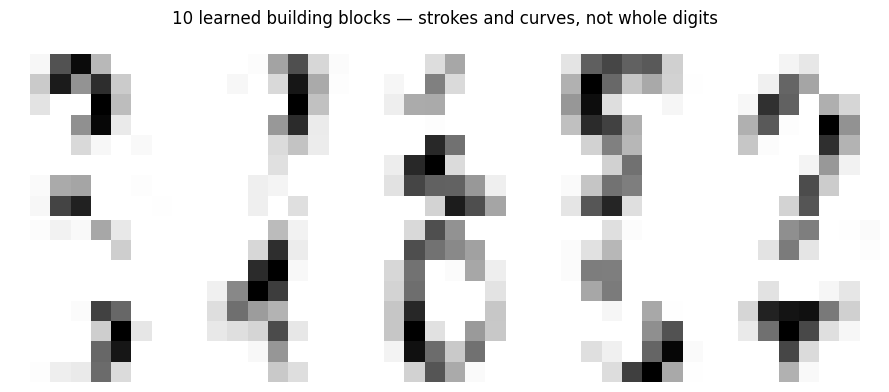

In [20]:
fig, axes = plt.subplots(2, 5, figsize=(9, 4))
for ax, comp in zip(axes.ravel(), C_img):
    ax.imshow(comp.reshape(8, 8), cmap="gray_r")
    ax.axis("off")
fig.suptitle("10 learned building blocks — strokes and curves, not whole digits")
plt.tight_layout()
plt.show()

In [21]:
recon = B_img @ C_img
print(f"Numbers stored: original {A_img.size:,}  →  factorized {B_img.size + C_img.size:,}")
print(f"Relative error: {np.linalg.norm(A_img - recon) / np.linalg.norm(A_img):.1%}")

Numbers stored: original 25,600  →  factorized 4,640
Relative error: 30.3%


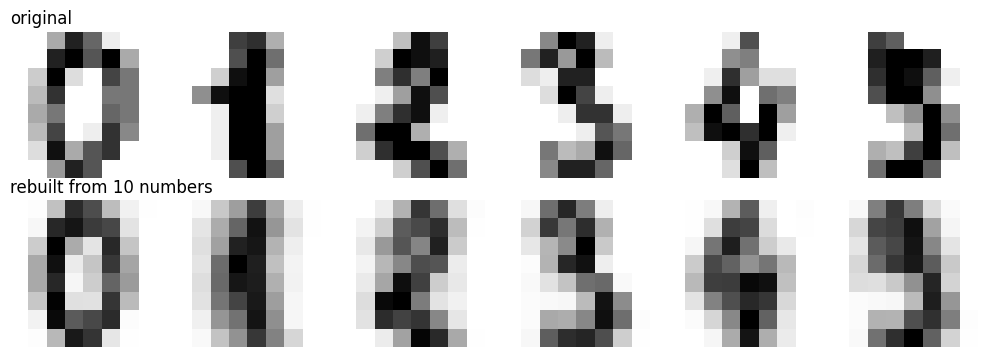

In [22]:
fig, axes = plt.subplots(2, 6, figsize=(10, 3.6))
for k in range(6):
    axes[0, k].imshow(A_img[k].reshape(8, 8), cmap="gray_r"); axes[0, k].axis("off")
    axes[1, k].imshow(recon[k].reshape(8, 8), cmap="gray_r"); axes[1, k].axis("off")
axes[0, 0].set_title("original", loc="left"); axes[1, 0].set_title("rebuilt from 10 numbers", loc="left")
plt.tight_layout()
plt.show()

Each block is a stroke or curve; any digit is a **sum** of a few blocks. We store far fewer numbers (4,640
instead of 25,600, and the saving grows with image size) and still rebuild a recognisable, slightly blurrier
picture (about 30% error). The 10-number
vectors per image are features you can cluster or feed to a classifier, just like $p_u$ above.

*(For whole faces, the classic version of this idea uses PCA on flattened pixels, called "eigenfaces". PCA needs
a square matrix, so it first builds the 4096×4096 covariance matrix — a detail covered in the PCA notebook once
that is added.)*


## 10. Summary — revision cheat sheet

- **One idea, many methods**: $X \approx W H$, minimising reconstruction error. The methods differ only in the
  **constraints** on $W$ and $H$.
- **Frobenius norm** $\|A\|_F$: square every entry, add, square-root. Used to measure $\|R - UV^T\|_F$.
- **K-Means** = $X \approx ZC$ with $Z$ one-hot (hard). Its inertia equals $\|X - ZC\|_F^2$. **GMM** = same, but
  rows of $Z$ are fractions summing to 1 (soft).
- **NMF**: everything ≥ 0 → factors are "parts" you can read and add up.
- **Several signals** (bought / carted / removed): don't just add them (opposites cancel into nonsense); weights
  work but add fragile hyperparameters; best is to factorize each separately and combine at decision time.
- **Netflix Prize** upgrades: base $\hat r = q_i^T p_u$ → **regularization** ($\lambda$, stops memorizing) → **biases**
  ($\hat r = \mu + b_u + b_i + q_i^T p_u$) → **time** (biases and vectors drift). Trained with SGD; pick $d$ and
  $\lambda$ by test error, never by training error.
- **Feature engineering**: the learned $p_u$, $q_i$ vectors are dense, reusable, but not interpretable features
  — cluster them, find neighbours, feed other models.
- **Text and images** are matrices too: document × word, image × pixel. Factorize, and each document, word or
  image gets a short dense vector.

**Coming next**: more recommendation topics, once I've covered them.
